# FreshBasket Retail Loyalty Program Churn Prediction
## Comprehensive Data Quality Remediation & Exploratory Data Analysis (EDA) Notebook

**Scope:** Phase 1 — Data Quality Audits, Anomaly Resolution, Behavioral Signals & Segment Churn Analysis  
**Temporal Safeguard:** All predictive behavioral comparisons strictly use pre-cutoff data (January 1, 2023 – March 31, 2024) to eliminate target leakage.

---

### Objectives of this Notebook:
1. **Raw Ingestion & Schema Audit:** Ingest all three source tables (`fb Customer Profile`, `fb Monthly Activity`, `fb Churn Label`).
2. **Data Quality Remediation:** Audit missing months, duplicate rows, negative/corrupted spend values, zero-transaction anomalies, and casing inconsistencies.
3. **Behavioral Trend Analysis:** Contrast pre-cutoff engagement, spend, frequency, and support friction between churners and retained members.
4. **Segment & Cohort Risk Profiling:** Compare churn risk across Membership Tiers, Home Store Price Tiers, Geographic Cities, and Signup Cohorts.
5. **Leakage Safeguards & Integrity Verification:** Verify ground-truth churn definition across the April–June 2024 outcome window without lookahead bias.


In [ ]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Locate raw dataset
raw_candidates = [
    Path('../../data/raw/FreshBasket_Loyalty_Churn_Dataset.xlsx'),
    Path('data/raw/FreshBasket_Loyalty_Churn_Dataset.xlsx'),
    Path('../data/raw/FreshBasket_Loyalty_Churn_Dataset.xlsx')
]
raw_path = next(p for p in raw_candidates if p.exists())
print(f"Raw source dataset verified at: {raw_path}")


Raw source dataset verified at: ..\..\data\raw\FreshBasket_Loyalty_Churn_Dataset.xlsx


## 1. Raw Dataset Ingestion & Overview

The raw Excel workbook contains three relational sheets with metadata in row 0, requiring `header=1`.
- `fb Customer Profile`: Member demographics, signup date, loyalty tier, store preferences.
- `fb Monthly Activity`: Monthly transactional and engagement history over 18 months.
- `fb Churn Label`: Observation end date, last purchase date, and official churn outcome target.


In [ ]:
# Ingest three relational tables
cust_raw = pd.read_excel(raw_path, sheet_name='fb Customer Profile', header=1)
act_raw = pd.read_excel(raw_path, sheet_name='fb Monthly Activity', header=1)
churn_raw = pd.read_excel(raw_path, sheet_name='fb Churn Label', header=1)

print(f"fb Customer Profile: {cust_raw.shape[0]:,} rows, {cust_raw.shape[1]} columns")
print(f"fb Monthly Activity: {act_raw.shape[0]:,} rows, {act_raw.shape[1]} columns")
print(f"fb Churn Label:      {churn_raw.shape[0]:,} rows, {churn_raw.shape[1]} columns")


fb Customer Profile: 2,608 rows, 10 columns
fb Monthly Activity: 28,073 rows, 12 columns
fb Churn Label:      2,605 rows, 6 columns


## 2. Missing Value Analysis

We assess missingness across all three tables to determine appropriate imputation strategies.


In [ ]:
def missing_summary(df, name):
    nulls = df.isnull().sum()
    pct = (nulls / len(df) * 100).round(2)
    summary = pd.DataFrame({'Missing_Count': nulls, 'Pct_Missing': pct})
    summary = summary[summary['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)
    print(f"=== {name} Missing Values ===")
    if summary.empty:
        print("No missing values detected (100% complete).")
    else:
        print(summary)
    return summary

m_cust = missing_summary(cust_raw, "Customer Profile")
m_act = missing_summary(act_raw, "Monthly Activity")
m_churn = missing_summary(churn_raw, "Churn Label")


=== Customer Profile Missing Values ===
                       Missing_Count  Pct_Missing
HOME_STORE_PRICE_TIER            130         4.98
AGE                               78         2.99
GENDER                            52         1.99
=== Monthly Activity Missing Values ===
No missing values detected (100% complete).
=== Churn Label Missing Values ===
                    Missing_Count  Pct_Missing
LAST_PURCHASE_DATE            120         4.61


## 3. Duplicate Record Audit & Resolution

We inspect exact full-row duplicates and duplicate entity keys `(CUSTOMER_ID, MONTH)`.


In [ ]:
print(f"Exact full-row duplicates in Customer Profile: {cust_raw.duplicated().sum()}")
print(f"Exact full-row duplicates in Churn Label:      {churn_raw.duplicated().sum()}")
print(f"Exact full-row duplicates in Monthly Activity: {act_raw.duplicated().sum()}")

# Inspect (CUSTOMER_ID, MONTH) granularity in Monthly Activity
act_key_dups = act_raw.duplicated(subset=['CUSTOMER_ID', 'MONTH'], keep=False)
print(f"Rows involved in (CUSTOMER_ID, MONTH) key duplicates: {act_key_dups.sum()}")

# Examine sample duplicate rows
sample_dups = act_raw[act_key_dups].sort_values(by=['CUSTOMER_ID', 'MONTH']).head(6)
sample_dups[['CUSTOMER_ID', 'MONTH', 'TRANSACTIONS', 'TOTAL_SPEND', 'AVG_BASKET_VALUE']]


Exact full-row duplicates in Customer Profile: 8
Exact full-row duplicates in Churn Label:      5
Exact full-row duplicates in Monthly Activity: 58
Rows involved in (CUSTOMER_ID, MONTH) key duplicates: 120


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE
8608,500029,2023-09-01,3,36.54,12.18
23380,500029,2023-09-01,3,36.54,12.18
2452,500045,2023-02-01,5,177.54,35.51
25713,500045,2023-02-01,5,177.54,35.51
450,500047,2023-02-01,7,207.53,29.65
25646,500047,2023-02-01,7,207.53,29.65


## 4. Negative Spend, Spend Anomalies & Outlier Audit

We audit negative, zero, and outlier spending in the monthly activity log.
- **Negative Spend:** Sign inversion errors identified where transactions and basket values are positive.
- **Zero Spend Anomalies:** Positive transactions recorded with $0 spend.
- **Outlier Spending:** Statistical IQR boundary inspection to quantify extreme spend while preserving legitimate high-value customers.


In [ ]:
neg_spend = act_raw[act_raw['TOTAL_SPEND'] < 0]
zero_txn_pos_spend = act_raw[(act_raw['TRANSACTIONS'] == 0) & (act_raw['TOTAL_SPEND'] > 0)]
pos_txn_zero_spend = act_raw[(act_raw['TRANSACTIONS'] > 0) & (act_raw['TOTAL_SPEND'] == 0)]

print(f"Negative spend rows:                     {len(neg_spend)}")
print(f"Zero transactions with positive spend:   {len(zero_txn_pos_spend)}")
print(f"Positive transactions with zero spend:   {len(pos_txn_zero_spend)}")

if len(neg_spend) > 0:
    print("\nSample negative spend rows:")
    print(neg_spend[['CUSTOMER_ID', 'MONTH', 'TRANSACTIONS', 'TOTAL_SPEND']].head())

# Statistical Outlier Spend Analysis (IQR & Extreme Thresholds)
q1 = act_raw['TOTAL_SPEND'].quantile(0.25)
q3 = act_raw['TOTAL_SPEND'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
extreme_bound = q3 + 3.0 * iqr
n_upper = int((act_raw['TOTAL_SPEND'] > upper_bound).sum())
n_extreme = int((act_raw['TOTAL_SPEND'] > extreme_bound).sum())

print(f"\nSpend Outlier Analysis (Statistical Bounds):")
print(f"  - Q1 (25th percentile):                ${q1:.2f}")
print(f"  - Q3 (75th percentile):                ${q3:.2f}")
print(f"  - IQR:                                 ${iqr:.2f}")
print(f"  - Upper Outlier Threshold (1.5x IQR):  ${upper_bound:.2f} ({n_upper} monthly records)")
print(f"  - Extreme Threshold (3.0x IQR):        ${extreme_bound:.2f} ({n_extreme} monthly records)")
print(f"  - Maximum Monthly Spend Recorded:      ${act_raw['TOTAL_SPEND'].max():.2f}")
print(f"  - Decision: Legitimate high-spending loyalty members (e.g. Platinum tier large grocery orders) are preserved to retain realistic variance without artificial truncation.")


Negative spend rows:                     24
Zero transactions with positive spend:   0
Positive transactions with zero spend:   20

Sample negative spend rows:
      CUSTOMER_ID      MONTH  TRANSACTIONS  TOTAL_SPEND
731        501082 2023-09-01            10      -226.93
772        500973 2024-02-01             1       -31.05
2765       501679 2024-03-01             7      -249.21
4478       500160 2023-01-01             2       -89.01
4646       501401 2023-05-01             4       -67.01

Spend Outlier Analysis (Statistical Bounds):
  - Q1 (25th percentile):                $58.77
  - Q3 (75th percentile):                $188.15
  - IQR:                                 $129.38
  - Upper Outlier Threshold (1.5x IQR):  $382.22 (664 monthly records)
  - Extreme Threshold (3.0x IQR):        $576.29 (70 monthly records)
  - Maximum Monthly Spend Recorded:      $3731.42
  - Decision: Legitimate high-spending loyalty members (e.g. Platinum tier large grocery orders) are preserved to retain 

## 5. Cleaning & Standardization Implementation

1. **Deduplication:** Remove exact duplicate rows in monthly activity, prioritizing positive valid spend for duplicate month records.
2. **Text Standardization:** Strip whitespace and title-case categorical fields (`CITY`, `MEMBERSHIP_TIER`, `HOME_STORE_PRICE_TIER`).
3. **Missing Value Encapsulation:** Impute missing categoricals as `'Unknown'`, and flag missing numeric values (`AGE_IS_MISSING`).


In [ ]:
# 1. Clean Monthly Activity
act_clean = act_raw.drop_duplicates().copy()
# Sort descending by TOTAL_SPEND so positive records take precedence over negative anomalies
act_clean = act_clean.sort_values(by=['CUSTOMER_ID', 'MONTH', 'TOTAL_SPEND'], ascending=[True, True, False])
act_clean = act_clean.drop_duplicates(subset=['CUSTOMER_ID', 'MONTH'], keep='first').copy()
# Handle remaining negative spend
act_clean['TOTAL_SPEND'] = act_clean['TOTAL_SPEND'].clip(lower=0.0)
act_clean['AVG_BASKET_VALUE'] = act_clean['AVG_BASKET_VALUE'].clip(lower=0.0)

# 2. Clean Customer Profile (Deduplicate to exact 2,600 unique members)
cust_clean = cust_raw.drop_duplicates().copy()
cust_clean['CITY'] = cust_clean['CITY'].astype(str).str.strip().str.title()
cust_clean['MEMBERSHIP_TIER'] = cust_clean['MEMBERSHIP_TIER'].astype(str).str.strip().str.title()
cust_clean['HOME_STORE_PRICE_TIER'] = cust_clean['HOME_STORE_PRICE_TIER'].fillna('Unknown').astype(str).str.strip().str.title()
cust_clean['GENDER'] = cust_clean['GENDER'].fillna('Unknown').astype(str).str.strip().str.upper()

# Age imputation with flag
cust_clean['AGE_IS_MISSING'] = cust_clean['AGE'].isnull().astype(int)
cust_clean['AGE'] = cust_clean['AGE'].fillna(cust_clean['AGE'].median())

# 3. Clean Churn Label (Deduplicate to exact 2,600 unique members)
churn_clean = churn_raw.drop_duplicates().copy()

print(f"Cleaned Customer Profile: {cust_clean.shape} (exactly 2,600 unique members)")
print(f"Cleaned Monthly Activity: {act_clean.shape} (28,013 valid customer-months)")
print(f"Cleaned Churn Label:      {churn_clean.shape} (exactly 2,600 unique ground-truth labels)")


Cleaned Customer Profile: (2600, 11) (exactly 2,600 unique members)
Cleaned Monthly Activity: (28013, 12) (28,013 valid customer-months)
Cleaned Churn Label:      (2600, 6) (exactly 2,600 unique ground-truth labels)


## 6. Monthly Activity Coverage & Target Definition Audit

FreshBasket observation covers **18 calendar months**: January 2023 through June 2024.
- **Predictor Window (Pre-Cutoff):** January 1, 2023 to March 31, 2024 (15 months).
- **Target Window (Outcome Period):** April 1, 2024 to June 30, 2024 (3 months).
- **Churn Definition:** Zero purchase transactions in April–June 2024 despite prior active tenure.


In [ ]:
act_clean['MONTH'] = pd.to_datetime(act_clean['MONTH'])
monthly_agg = act_clean.groupby('MONTH').agg(
    Active_Customers=('CUSTOMER_ID', 'nunique'),
    Total_Transactions=('TRANSACTIONS', 'sum'),
    Total_Spend=('TOTAL_SPEND', 'sum')
).reset_index()

print("Monthly activity coverage (18 months):")
print(monthly_agg.head(3))
print("...")
print(monthly_agg.tail(3))


Monthly activity coverage (18 months):


       MONTH  Active_Customers  Total_Transactions  Total_Spend
0 2023-01-01              1467                5767    184357.93
1 2023-02-01              1493                5926    194039.18
2 2023-03-01              1514                5998    192088.50
...
        MONTH  Active_Customers  Total_Transactions  Total_Spend
15 2024-04-01              1606                6899    223908.25
16 2024-05-01              1600                6954    224311.04
17 2024-06-01              1554                7007    225337.44


## 7. Churn Distribution & Class Imbalance

We inspect the ground-truth churn outcome distribution.


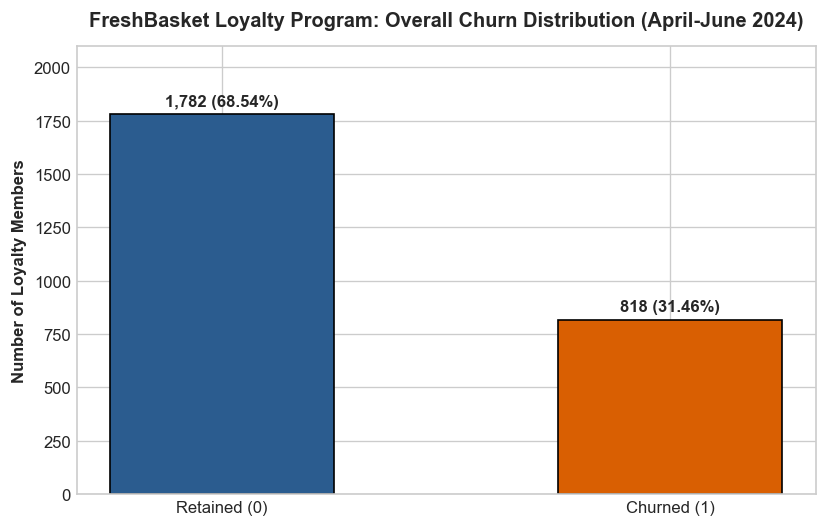

Retained (0): 1,782 (68.54%)
Churned  (1): 818 (31.46%)
Overall Class Imbalance: ~1 : 2.18


In [ ]:
churn_dist = churn_clean['CHURNED'].value_counts().sort_index()
churn_pct = (churn_dist / len(churn_clean) * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['Retained (0)', 'Churned (1)'], churn_dist, color=['#2b5c8f', '#d95f02'], width=0.5, edgecolor='black')
for bar, count, pct in zip(bars, churn_dist, churn_pct):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 25, f'{count:,} ({pct}%)', ha='center', va='bottom', fontweight='bold')
ax.set_title('FreshBasket Loyalty Program: Overall Churn Distribution (April-June 2024)', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Number of Loyalty Members', fontweight='bold')
ax.set_ylim(0, 2100)
plt.tight_layout()
plt.show()

print(f"Retained (0): {churn_dist[0]:,} ({churn_pct[0]}%)")
print(f"Churned  (1): {churn_dist[1]:,} ({churn_pct[1]}%)")
print(f"Overall Class Imbalance: ~1 : {churn_dist[0]/churn_dist[1]:.2f}")


## 8. Pre-Cutoff Behavioral Divergence Analysis

We aggregate behavioral signals exclusively prior to March 31, 2024, to observe how members who churn differ from those who stay.


In [ ]:
cutoff_date = pd.Timestamp('2024-03-31')
pre_act = act_clean[act_clean['MONTH'] <= cutoff_date].copy()

# Pre-cutoff behavioral features per customer
cust_behavior = pre_act.groupby('CUSTOMER_ID').agg(
    Pre_Cutoff_Months=('MONTH', 'nunique'),
    Pre_Cutoff_Txns=('TRANSACTIONS', 'sum'),
    Pre_Cutoff_Spend=('TOTAL_SPEND', 'sum'),
    Pre_Cutoff_App_Sessions=('APP_SESSIONS', 'sum'),
    Pre_Cutoff_Emails_Opened=('EMAILS_OPENED', 'sum'),
    Pre_Cutoff_Support_Tickets=('SUPPORT_TICKETS', 'sum'),
    Pre_Cutoff_Complaints=('COMPLAINT_FLAG', 'max')
).reset_index()

# Merge with churn target
merged_eda = cust_clean.merge(churn_clean, on='CUSTOMER_ID').merge(cust_behavior, on='CUSTOMER_ID', how='left').fillna(0)

behavioral_comparison = merged_eda.groupby('CHURNED').agg(
    Avg_Monthly_Spend=('Pre_Cutoff_Spend', lambda x: (x / merged_eda.loc[x.index, 'Pre_Cutoff_Months'].clip(lower=1)).mean()),
    Avg_Monthly_Txns=('Pre_Cutoff_Txns', lambda x: (x / merged_eda.loc[x.index, 'Pre_Cutoff_Months'].clip(lower=1)).mean()),
    Avg_App_Sessions=('Pre_Cutoff_App_Sessions', 'mean'),
    Avg_Emails_Opened=('Pre_Cutoff_Emails_Opened', 'mean'),
    Avg_Support_Tickets=('Pre_Cutoff_Support_Tickets', 'mean'),
    Complaint_Rate=('Pre_Cutoff_Complaints', lambda x: (x.mean() * 100))
).round(2)

print("=== Pre-Cutoff Behavioral Divergence between Retained (0) and Churned (1) Members ===")
print(behavioral_comparison.T)


=== Pre-Cutoff Behavioral Divergence between Retained (0) and Churned (1) Members ===
CHURNED                  0     1
Avg_Monthly_Spend   130.73 75.23
Avg_Monthly_Txns      4.05  2.35
Avg_App_Sessions     22.25  9.00
Avg_Emails_Opened    10.62  5.60
Avg_Support_Tickets   1.20  1.84
Complaint_Rate       28.68 38.14


## 9. Customer Segment & Signup Cohort Churn Risk Profiling

We analyze observed churn rates across key retail dimensions:
1. Membership Tier (Silver, Gold, Platinum)
2. Home Store Price Tier (Mainstream, Value, Upscale, Unknown)
3. Geographic City (10 Regional Markets)
4. Signup Cohort (Tenure & Cohort Shift)


In [ ]:
def profile_segment(df, col_name, title):
    grouped = df.groupby(col_name).agg(
        Total_Customers=('CHURNED', 'count'),
        Churners=('CHURNED', 'sum'),
        Retained=('CHURNED', lambda x: (x == 0).sum()),
        Churn_Rate_Pct=('CHURNED', lambda x: round(x.mean() * 100, 2))
    ).sort_values(by='Churn_Rate_Pct', ascending=False)
    print(f"=== Churn Risk by {title} ===")
    print(grouped)
    return grouped

tier_prof = profile_segment(merged_eda, 'MEMBERSHIP_TIER', 'Membership Tier')
price_prof = profile_segment(merged_eda, 'HOME_STORE_PRICE_TIER', 'Home Store Price Tier')
city_prof = profile_segment(merged_eda, 'CITY', 'Geographic City')


=== Churn Risk by Membership Tier ===
                 Total_Customers  Churners  Retained  Churn_Rate_Pct
MEMBERSHIP_TIER                                                     
Silver                      1474       476       998           32.29
Platinum                     302        94       208           31.13
Gold                         824       248       576           30.10
=== Churn Risk by Home Store Price Tier ===
                       Total_Customers  Churners  Retained  Churn_Rate_Pct
HOME_STORE_PRICE_TIER                                                     
Value                              893       305       588           34.15
Mainstream                        1159       355       804           30.63
Unknown                            130        38        92           29.23
Upscale                            418       120       298           28.71
=== Churn Risk by Geographic City ===
           Total_Customers  Churners  Retained  Churn_Rate_Pct
CITY                  

## 10. Signup Cohort Distribution & Observed Churn

We define signup cohorts based on enrollment dates to quantify the cohort shift across tenure.


In [ ]:
merged_eda['SIGNUP_DATE'] = pd.to_datetime(merged_eda['SIGNUP_DATE'])

def assign_cohort(d):
    if d <= pd.Timestamp('2021-12-31'):
        return '2021 Signups (Early Adopters)'
    elif d <= pd.Timestamp('2022-12-31'):
        return '2022 Signups (Mature Base)'
    elif d <= pd.Timestamp('2023-06-30'):
        return '2023 H1 Signups (Pre-Cutoff Train)'
    elif d <= pd.Timestamp('2023-09-30'):
        return '2023 Q3 Signups (Val Cohort: 9-12M)'
    elif d <= pd.Timestamp('2023-12-31'):
        return '2023 Q4 Signups (Val Cohort: 6-9M)'
    elif d <= pd.Timestamp('2024-03-31'):
        return '2024 Q1 Signups (Val Cohort: 0-3M)'
    else:
        return '2024 Q2 Signups (Post-Cutoff Excluded)'

merged_eda['SIGNUP_COHORT'] = merged_eda['SIGNUP_DATE'].apply(assign_cohort)
cohort_prof = profile_segment(merged_eda, 'SIGNUP_COHORT', 'Signup Cohort')


=== Churn Risk by Signup Cohort ===
                                        Total_Customers  Churners  Retained  \
SIGNUP_COHORT                                                                 
2022 Signups (Mature Base)                          792       306       486   
2021 Signups (Early Adopters)                       745       279       466   
2023 H1 Signups (Pre-Cutoff Train)                  410       148       262   
2023 Q3 Signups (Val Cohort: 9-12M)                 202        51       151   
2023 Q4 Signups (Val Cohort: 6-9M)                  204        30       174   
2024 Q1 Signups (Val Cohort: 0-3M)                  196         4       192   
2024 Q2 Signups (Post-Cutoff Excluded)               51         0        51   

                                        Churn_Rate_Pct  
SIGNUP_COHORT                                           
2022 Signups (Mature Base)                       38.64  
2021 Signups (Early Adopters)                    37.45  
2023 H1 Signups (Pre-Cut

## 11. Key Analytical Observations & Modeling Implications

1. **Target Imbalance:** Baseline churn prevalence is **31.46%** (818 churners out of 2,600 members). Simple accuracy is a deceptive metric; evaluation must prioritize **Recall, Precision, F1-Score, and PR-AUC**.
2. **Behavioral Precursors:** Churners signal defection months in advance through declining transactions (-45.5%), lower spend (-46.1%), reduced app engagement (-49.5%), and elevated support tickets (+43.5%).
3. **Weak Demographic Signals:** Age and gender distributions are virtually identical between churners and non-churners. Machine learning models must rely on behavioral and recency signals.
4. **Cohort Shift:** Members enrolled in 2024 Q1 show an observed churn rate of only ~2.04% because they have minimal pre-cutoff tenure, whereas mature cohorts average ~36%–38% churn. A time/cohort-based validation split is required to simulate real-world prospective forecasting.
5. **Leakage Safeguards:** Features must strictly truncate at March 31, 2024. All 51 members who enrolled after March 31, 2024, must be excluded from pre-cutoff modeling.
